In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
# first column is the college name, so I use it as the index
df = pd.read_csv('University_Data(in).csv', index_col=0)
df.head()

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


## Initial Data Analysis

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 777 entries, Abilene Christian University to York College of Pennsylvania
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Private      777 non-null    object 
 1   Apps         777 non-null    int64  
 2   Accept       777 non-null    int64  
 3   Enroll       777 non-null    int64  
 4   Top10perc    777 non-null    int64  
 5   Top25perc    777 non-null    int64  
 6   F.Undergrad  777 non-null    int64  
 7   P.Undergrad  777 non-null    int64  
 8   Outstate     777 non-null    int64  
 9   Room.Board   777 non-null    int64  
 10  Books        777 non-null    int64  
 11  Personal     777 non-null    int64  
 12  PhD          777 non-null    int64  
 13  Terminal     777 non-null    int64  
 14  S.F.Ratio    777 non-null    float64
 15  perc.alumni  777 non-null    int64  
 16  Expend       777 non-null    int64  
 17  Grad.Rate    777 non-null    int64  
dtypes: 

In [4]:
print('Missing values:', df.isnull().sum().sum())
print(df['Private'].value_counts())
df.describe()

Missing values: 0
Private
Yes    565
No     212
Name: count, dtype: int64


,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
count,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.00000
mean,3001.638353,2018.804376,779.972973,27.558559,55.796654,3699.907336,855.298584,10440.669241,4357.526384,549.380952,1340.642214,72.660232,79.702703,14.089704,22.743887,9660.171171,65.46332
std,3870.201484,2451.113971,929.176190,17.640364,19.804778,4850.420531,1522.431887,4023.016484,1096.696416,165.105360,677.071454,16.328155,14.722359,3.958349,12.391801,5221.768440,17.17771
min,81.000000,72.000000,35.000000,1.000000,9.000000,139.000000,1.000000,2340.000000,1780.000000,96.000000,250.000000,8.000000,24.000000,2.500000,0.000000,3186.000000,10.00000
25%,776.000000,604.000000,242.000000,15.000000,41.000000,992.000000,95.000000,7320.000000,3597.000000,470.000000,850.000000,62.000000,71.000000,11.500000,13.000000,6751.000000,53.00000
50%,1558.000000,1110.000000,434.000000,23.000000,54.000000,1707.000000,353.000000,9990.000000,4200.000000,500.000000,1200.000000,75.000000,82.000000,13.600000,21.000000,8377.000000,65.00000
75%,3624.000000,2424.000000,902.000000,35.000000,69.000000,4005.000000,967.000000,12925.000000,5050.000000,600.000000,1700.000000,85.000000,92.000000,16.500000,31.000000,10830.000000,78.00000
max,48094.000000,26330.000000,6392.000000,96.000000,100.000000,31643.000000,21836.000000,21700.000000,8124.000000,2340.000000,6800.000000,103.000000,100.000000,39.800000,64.000000,56233.000000,118.00000


There are 777 colleges and 18 columns, with **no missing values**. The `Private` column is text (565 Yes, 212 No) and everything else is numeric.

In `describe()` I can see `Grad.Rate` has a max of **118**, which looks wrong because a graduation rate cannot be over 100%.


### Plotting Room.Board vs Grad.Rate and Outstate vs F.Undergrad.

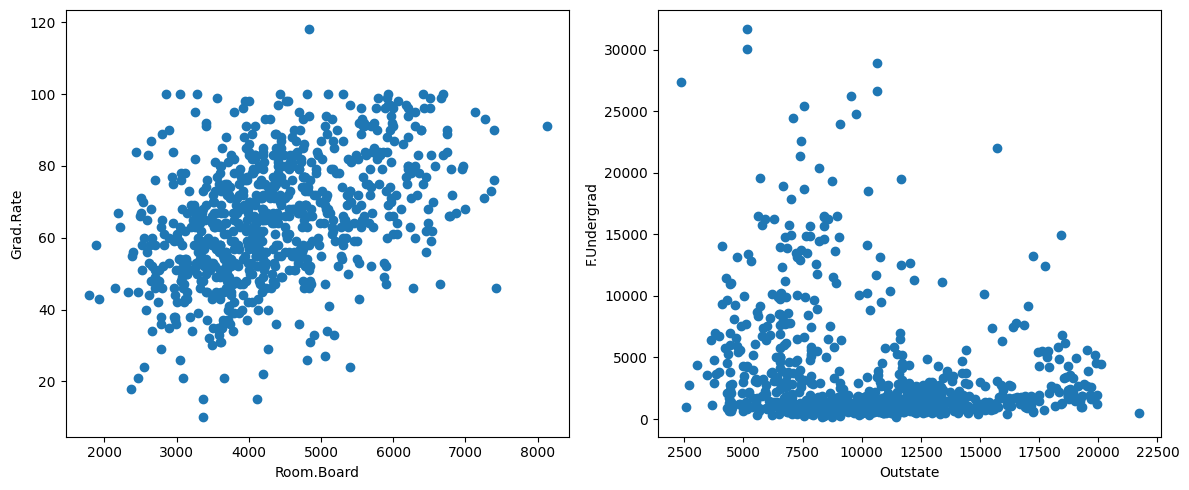

In [5]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(df['Room.Board'], df['Grad.Rate'])
plt.xlabel('Room.Board')
plt.ylabel('Grad.Rate')

plt.subplot(1,2,2)
plt.scatter(df['Outstate'], df['F.Undergrad'])
plt.xlabel('Outstate')
plt.ylabel('F.Undergrad')

plt.tight_layout()

* **Room.Board vs Grad.Rate:** one point is above 100% graduation rate. This is a mistake in the data.

I will fix the wrong graduation rate.

In [6]:
# which college has Grad.Rate over 100?
print(df[df['Grad.Rate'] > 100][['Grad.Rate']])

# a graduation rate cannot be over 100, so set it to 100
df.loc[df['Grad.Rate'] > 100, 'Grad.Rate'] = 100
print('New max Grad.Rate:', df['Grad.Rate'].max())

                   Grad.Rate
Cazenovia College        118
New max Grad.Rate: 100


## K-Means Model
Create a K-Means model with 2 clusters and fit it on all the columns **except** `Private`.

In [7]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans.fit(df.drop('Private', axis=1))

KMeans(n_clusters=2, n_init=10, random_state=42)

In [8]:
# cluster centers (a few features) and how the clusters line up with Private
centers = pd.DataFrame(kmeans.cluster_centers_, columns=df.drop('Private', axis=1).columns)
print(centers[['Apps', 'Enroll', 'F.Undergrad', 'Outstate']].round(0))
pd.crosstab(df['Private'], kmeans.labels_, rownames=['Private'], colnames=['Cluster'])

      Apps  Enroll  F.Undergrad  Outstate
0   1813.0   491.0       2189.0   10396.0
1  10363.0  2570.0      13062.0   10719.0


Cluster,0,1
Private,,
No,138,74
Yes,531,34


K-Means gives the clusters the numbers 0 and 1 randomly, so they do not automatically match Yes / No. Looking at the table, **cluster 0** has most of the Private colleges (531 of 565). Its centre has far fewer applications, enrolled students and undergraduates, so it is the cluster of smaller colleges. I will call cluster 0 = Private (Yes) and cluster 1 = Public (No).

## Evaluation

In [9]:
# convert cluster numbers to Yes / No
predicted = np.where(kmeans.labels_ == 0, 'Yes', 'No')

print(confusion_matrix(df['Private'], predicted))
print()
print(classification_report(df['Private'], predicted))

[[ 74 138]
 [ 34 531]]

              precision    recall  f1-score   support

          No       0.69      0.35      0.46       212
         Yes       0.79      0.94      0.86       565

    accuracy                           0.78       777
   macro avg       0.74      0.64      0.66       777
weighted avg       0.76      0.78      0.75       777



Text(0, 0.5, 'F.Undergrad')

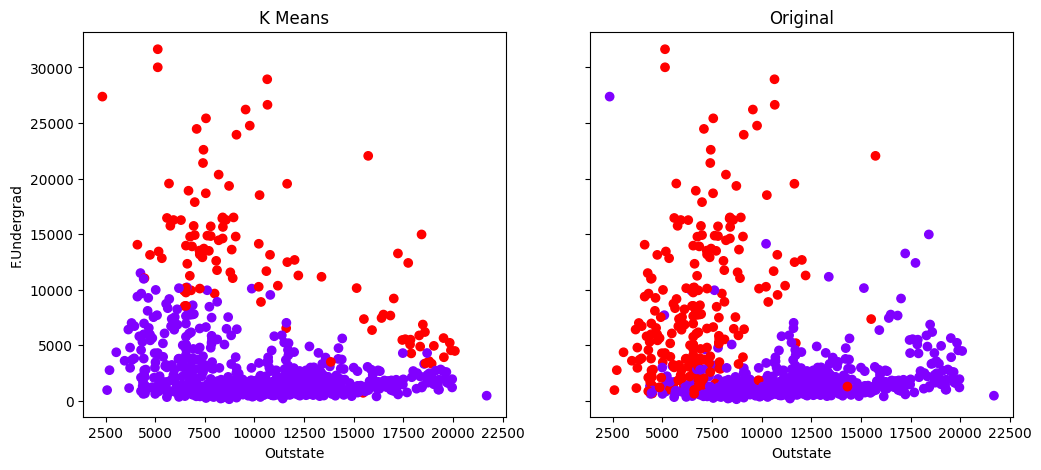

In [10]:
# K-Means clusters vs the real labels
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(12,5))
ax1.set_title('K Means')
ax1.scatter(df['Outstate'], df['F.Undergrad'], c=kmeans.labels_, cmap='rainbow')
ax2.set_title('Original')
ax2.scatter(df['Outstate'], df['F.Undergrad'], c=(df['Private'] == 'No').astype(int), cmap='rainbow')
ax1.set_xlabel('Outstate')
ax2.set_xlabel('Outstate')
ax1.set_ylabel('F.Undergrad')

## Conclusion

* K-Means with 2 clusters got an accuracy of about **78%**.
* It does well on **Private** colleges (recall about 0.94) but poorly on **Public** ones (only about 35% found).
* The two clusters mostly split colleges by **size** (`Apps`, `Enroll`, `F.Undergrad`), while `Outstate` tuition is almost the same in both centres. Large public universities end up in cluster 1, but many smaller public colleges look like private ones and land in cluster 0.
* The only outlier I fixed was the graduation rate of 118, set to 100.